# Repaso AMq1 · 2 — Modelos, métricas y Optuna

**Objetivo de la clase:** recordar cómo llegamos a XGBoost, qué significan sus hiperparámetros y
cómo los buscamos con Optuna. En MLOps vamos a *registrar* esa búsqueda en MLflow, así que conviene
tenerla fresca.

In [1]:
from helpers import check, quiz, safe_check

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import interact, widgets
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from burnout.config import BEST_PARAMS_AMQ1, LABELS, SEED
from burnout.data import load_raw, make_split
from burnout.model import build_preprocessor, feature_importance, make_pipeline, test_metrics

X_train, X_test, y_train, y_test = make_split(load_raw())
print(f"train: {X_train.shape}  test: {X_test.shape}")

train: (40000, 12)  test: (10000, 12)


## 1. La tabla final de AMq1

| Modelo | F1 macro CV | F1 macro test |
|---|---:|---:|
| **XGBoost (Optuna)** | 0,5385 | **0,5405** |
| Random Forest | 0,5363 | 0,5349 |
| Regresión logística | 0,5335 | 0,5303 |
| SVM (lineal) | 0,5309 | 0,5287 |
| KNN | 0,5247 | 0,5231 |
| Árbol de decisión | 0,5246 | 0,5222 |
| Dummy | — | 0,1981 |

Todas las diferencias son chicas: el dataset (probablemente sintético) tiene un techo cercano a 0,54.
Elegimos XGBoost porque fue el mejor en CV y en test, con un intervalo de confianza que no se
superpone con casi ningún otro.

Arranquemos por la referencia: el **Dummy**.

In [2]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy → F1 macro test: {f1_score(y_test, dummy.predict(X_test), average='macro'):.4f}")

Dummy → F1 macro test: 0.1981


## 2. 🎛️ Sobreajuste con un árbol de decisión
Mové `max_depth`: con árboles muy profundos el F1 en train sube a casi 1 pero en test **baja**.
Es el clásico sobreajuste.

In [3]:
resultados_arbol = {}


@interact(max_depth=widgets.IntSlider(min=1, max=30, value=5))
def arbol(max_depth):
    modelo = Pipeline([("prep", build_preprocessor()),
                       ("tree", DecisionTreeClassifier(max_depth=max_depth, random_state=SEED))])
    modelo.fit(X_train, y_train)
    tr = f1_score(y_train, modelo.predict(X_train), average="macro")
    te = f1_score(y_test, modelo.predict(X_test), average="macro")
    resultados_arbol[max_depth] = (tr, te)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    prof = sorted(resultados_arbol)
    ax.plot(prof, [resultados_arbol[p][0] for p in prof], "o-", label="train")
    ax.plot(prof, [resultados_arbol[p][1] for p in prof], "o-", label="test")
    ax.set(xlabel="max_depth (probadas hasta ahora)", ylabel="F1 macro", ylim=(0.3, 1.02),
           title=f"max_depth={max_depth} → train {tr:.3f} · test {te:.3f}")
    ax.legend()
    plt.show()

interactive(children=(IntSlider(value=5, description='max_depth', max=30, min=1), Output()), _dom_classes=('wi…

## 3. XGBoost: qué hace cada hiperparámetro

| Hiperparámetro | Qué controla | Más alto → |
|---|---|---|
| `n_estimators` | cantidad de árboles | más capacidad (y más tiempo) |
| `learning_rate` | cuánto aporta cada árbol | aprende rápido, pero puede sobreajustar |
| `max_depth` | profundidad de cada árbol | interacciones más complejas |
| `min_child_weight` | mínimo "peso" por hoja | árboles más conservadores |
| `subsample` / `colsample_bytree` | fracción de filas / columnas por árbol | menos aleatoriedad |
| `reg_alpha` / `reg_lambda` | regularización L1 / L2 | modelo más simple |
| `gamma` | ganancia mínima para dividir | menos divisiones |

### 🎛️ Probá combinaciones (validación cruzada de 3 folds sobre una muestra de 8.000 filas)

In [4]:
muestra = X_train.sample(8000, random_state=SEED).index
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)


@interact(
    n_estimators=widgets.IntSlider(min=50, max=500, step=50, value=100),
    learning_rate=widgets.FloatLogSlider(base=10, min=-2, max=-0.5, value=0.1),
    max_depth=widgets.IntSlider(min=1, max=10, value=6),
    gamma=widgets.FloatSlider(min=0, max=5, step=0.5, value=0),
    manual=True,
    manual_name="Evaluar",
)
def probar_xgb(n_estimators, learning_rate, max_depth, gamma):
    t0 = time.perf_counter()
    scores = cross_val_score(
        make_pipeline(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth, gamma=gamma),
        X_train.loc[muestra], y_train.loc[muestra], cv=cv3, scoring="f1_macro",
    )
    print(f"F1 macro CV: {scores.mean():.4f} ± {scores.std():.4f}   ({time.perf_counter() - t0:.1f} s)")
    print("Referencia AMq1 (40 pruebas de Optuna, CV completo): 0.5385")

interactive(children=(IntSlider(value=100, description='n_estimators', max=500, min=50, step=50), FloatLogSlid…

Pista: en AMq1 ganaron árboles **muy poco profundos** (`max_depth=2`) con `gamma` alto. Con estos
datos, el modelo que generaliza es simple.

## 4. Optuna en miniatura
Optuna propone hiperparámetros, mide el resultado y usa lo aprendido para proponer mejores
(muestreador **TPE**). Hagamos una búsqueda corta.

### ✏️ Ejercicio 1 — completá la función objetivo
Tiene que devolver el **promedio** del F1 macro de `cross_val_score` (usá `cv=cv3` y la `muestra`).

In [5]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objetivo(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    modelo = make_pipeline(n_estimators=150, **params)
    ...  # ← tu código acá: calculá los scores y devolvé su promedio

In [6]:
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
try:
    estudio.optimize(objetivo, n_trials=10)
    print(f"Mejor F1 macro: {estudio.best_value:.4f} con {estudio.best_params}")
except Exception as e:  # noqa: BLE001
    print(f"Todavía no funciona: {type(e).__name__}: {e}")

safe_check(
    "Ejercicio 1",
    lambda: estudio.best_value > 0.45,
    "`scores = cross_val_score(modelo, X_train.loc[muestra], y_train.loc[muestra], cv=cv3, "
    "scoring='f1_macro')` y `return scores.mean()`.",
)

[W 2026-11-11 11:44:58,528] Trial 0 failed with parameters: {'max_depth': 4, 'learning_rate': 0.2536999076681772, 'gamma': 3.6599697090570253} because of the following error: The value None could not be cast to float..


[W 2026-11-11 11:44:58,529] Trial 0 failed with value None.


[W 2026-11-11 11:44:58,530] Trial 1 failed with parameters: {'max_depth': 6, 'learning_rate': 0.01700037298921102, 'gamma': 0.7799726016810132} because of the following error: The value None could not be cast to float..


[W 2026-11-11 11:44:58,531] Trial 1 failed with value None.


[W 2026-11-11 11:44:58,533] Trial 2 failed with parameters: {'max_depth': 2, 'learning_rate': 0.19030368381735815, 'gamma': 3.005575058716044} because of the following error: The value None could not be cast to float..


[W 2026-11-11 11:44:58,533] Trial 2 failed with value None.


... (13 outputs left out)

[W 2026-11-11 11:44:58,549] Trial 9 failed with value None.


Todavía no funciona: ValueError: No trials are completed yet.


⏳ **Ejercicio 1**: todavía no. *Pista:* `scores = cross_val_score(modelo, X_train.loc[muestra], y_train.loc[muestra], cv=cv3, scoring='f1_macro')` y `return scores.mean()`. (error: `ValueError: No trials are completed yet.`)

False

<details><summary>Ver solución</summary>

```python
    scores = cross_val_score(modelo, X_train.loc[muestra], y_train.loc[muestra],
                             cv=cv3, scoring="f1_macro")
    return scores.mean()
```
</details>

## 5. El modelo final de AMq1

In [7]:
modelo = make_pipeline(**BEST_PARAMS_AMQ1).fit(X_train, y_train)
y_pred = modelo.predict(X_test)
pd.Series(test_metrics(y_test, y_pred)).round(4).to_frame("test")

,test
f1_macro,0.5365
balanced_accuracy,0.5236
recall_low,0.4945
recall_medium,0.6098
recall_high,0.4666


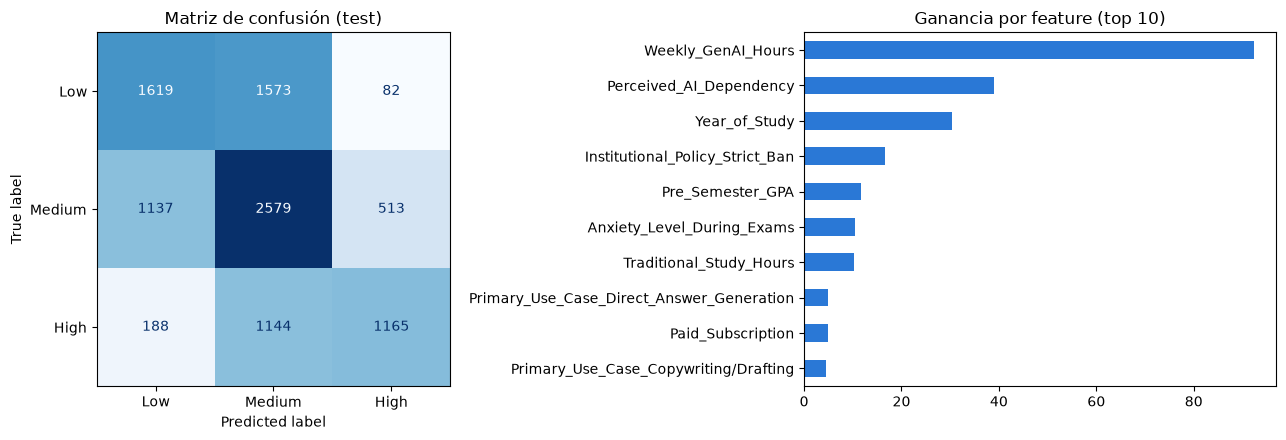

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=LABELS, cmap="Blues",
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión (test)")
axes[0].grid(False)
feature_importance(modelo).head(10).sort_values().plot.barh(ax=axes[1], color="#2a78d6")
axes[1].set_title("Ganancia por feature (top 10)")
plt.tight_layout()
plt.show()

In [9]:
quiz(
    "Según la matriz de confusión, ¿qué clase confunde más el modelo?",
    ["Low", "Medium", "High"],
    answer=1,
    explanation="Medium está en el medio: se confunde hacia ambos lados. Es esperable en una variable ordinal.",
)

**Según la matriz de confusión, ¿qué clase confunde más el modelo?**

ToggleButtons(options=('Low', 'Medium', 'High'), style=ToggleButtonsStyle(button_width='auto'), value=None)

Output()

## Resumen
- Métrica: **F1 macro**; referencia Dummy ≈ 0,20; techo práctico ≈ 0,54.
- Modelo: **XGBoost** con árboles poco profundos, encontrado con **Optuna** (TPE, 40 pruebas, CV de 5 folds).
- Este modelo es el que vamos a llevar a producción en MLOps. Sus hiperparámetros están en
  `burnout/config.py::BEST_PARAMS_AMQ1` y el test `tests/test_model.py` verifica que reproducimos el 0,5405.

Ya estás listo para las clases de MLOps: **C1 — Buenas prácticas**.